# Lab: triagem de mamografias

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/roc-imbalanced/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

**Nota de rigor metodológico (adicionada na resolução):** este lab usa `class_weight='balanced'` e reamostragem (`RandomUnderSampler`, `SMOTE`) para lidar com o forte desbalanceamento (2,3% de casos malignos). Em todos os passos, a reamostragem é feita **dentro de um `imblearn.pipeline.Pipeline`** (via `make_imb_pipeline`), que só reamostra durante o `.fit` — ou seja, só o `X_train`/`y_train` é tocado. A validação e o teste nunca são reamostrados, e todas as métricas (ROC AUC, AP, recall, precisão) são sempre calculadas sobre `X_val`/`X_test`, dados que nunca entraram no ajuste do modelo nem na escolha do limiar (o limiar é escolhido só na validação, no Passo 9, e usado uma única vez no teste, no Passo 10).

## Passo 1 — carregar e olhar a prevalência

**Preveja.** Microcalcificações são achados raros numa mamografia. Antes de rodar: você espera que elas sejam mais ou menos de 10% das regiões? Com essa prevalência, quanto de acurácia um modelo que nunca sinaliza nada conseguiria?

**Resposta (antes de rodar):** Microcalcificações malignas devem ser bem mais raras que 10% —
achados de triagem costumam ficar na faixa de 1-5% quando o alvo é especificamente "maligno" (e
não "qualquer achado"). Chuto algo entre 2% e 5%. Com essa prevalência, um modelo que nunca
sinaliza nada ("sempre benigno") acerta exatamente a fração de benignos, ou seja, seria 95-98% de
acurácia — um número que parece ótimo mas escondendo 100% dos casos malignos perdidos.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

mammo = fetch_openml(data_id=310, as_frame=True)
X = mammo.data                                   # 6 atributos numéricos por região
y = (mammo.target == '1').astype(int)            # o alvo é '-1' (benigno) ou '1' (maligno)
print(X.shape)
print(y.value_counts())
print(f"prevalence: {y.mean():.2%}")

(11183, 6)
class
0    10923
1      260
Name: count, dtype: int64
prevalence: 2.32%


**Resposta (depois de rodar):** Confirmado — são **11.183** regiões, 6 atributos, com **260**
malignas contra **10.923** benignas: prevalência de **2,32%**, dentro da faixa prevista (2-5%) e
bem abaixo de 10%. Um modelo "sempre benigno" acertaria exatamente 1 − 0,0232 = **97,68%** de
acurácia (confirmado no Passo 3) — um número enganosamente alto que não identifica nenhum caso
maligno.

## Passo 2 — divisão estratificada treino / validação / teste

**Preveja.** Por que estratificar importa mais aqui do que num conjunto equilibrado? Se a validação tiver cerca de 50 casos malignos, quanto de recall vale um único caso?

**Resposta (antes de rodar):** Com só 2,3% de casos malignos, uma divisão não estratificada
(aleatória pura) corre risco real de deixar uma fração de malignos bem diferente da global em
algum dos três conjuntos, só por sorte da amostragem — o que não aconteceria tanto num conjunto
equilibrado, onde qualquer split razoavelmente grande já preserva a proporção por lei dos grandes
números com folga. Se a validação tiver ~50 malignos, cada um vale 1/50 = **2 pontos percentuais**
de recall — um único caso classificado diferente já move o recall em 0,02, o que torna a métrica
bem mais "ruidosa"/discreta do que num conjunto maior ou mais balanceado.

In [2]:
from sklearn.model_selection import train_test_split

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                                  stratify=y_tmp, random_state=7)
for name, part in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f"{name:10s} {len(part):5d} rows  {part.sum():3d} malignant  ({part.mean():.2%})")

train       6709 rows  156 malignant  (2.33%)
validation  2237 rows   52 malignant  (2.32%)
test        2237 rows   52 malignant  (2.32%)


**Resposta (depois de rodar):** O split 60/20/20 estratificado deu **6.709** linhas de treino
(156 malignas, 2,33%), **2.237** de validação (**52** malignas, 2,32%) e **2.237** de teste (52
malignas, 2,32%) — as três proporções batem em duas casas decimais, exatamente o que a
estratificação garante. Com 52 malignos na validação, cada caso vale 1/52 ≈ **1,9 pontos
percentuais** de recall, confirmando a previsão: qualquer comparação de recall entre modelos
precisa ser lida com essa granularidade grosseira em mente.

## Passo 3 — um baseline que nunca sinaliza nada

**Preveja.** Qual vai ser a acurácia de responder "benigno" para todas as regiões? E o recall?

**Resposta (antes de rodar):** A acurácia deve ser igual à fração de benignos no treino,
perto de **97,7%** (1 − prevalência), e o recall deve ser exatamente **0** — um modelo que nunca
sinaliza "maligno" nunca encontra nenhum dos casos malignos, por definição.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred = dummy.predict(X_val)
print(f"accuracy {accuracy_score(y_val, pred):.4f}   recall {recall_score(y_val, pred):.3f}")

accuracy 0.9768   recall 0.000


**Resposta (depois de rodar):** Confirmado exatamente — acurácia **0,9768** (97,68%, igual à
fração de benignos na validação) e recall **0,000**. Esse é o número que qualquer modelo real
precisa superar não em acurácia (isso é fácil, 97,68% é um teto baixo para um problema raro), mas
em recall: a baseline não encontra absolutamente nenhum câncer, então "bater a baseline" só faz
sentido olhando para a curva ROC/PR, não para a acurácia isolada.

## Passo 4 — uma regressão logística no limiar padrão

**Preveja.** A acurácia vai superar a do baseline por muito ou por pouco? E o recall em 0,5: você espera perto de 0,9 ou bem abaixo disso, dado que só 2,3% das regiões são malignas?

**Resposta (antes de rodar):** A acurácia deve superar a baseline (97,68%) só por muito pouco
— talvez 98-99% — porque a baseline já começa muito alta num problema tão desbalanceado, então há
pouco espaço de melhora *em acurácia*. Já o recall em 0,5 deve ficar bem abaixo de 0,9: o limiar
0,5 é calibrado para a prevalência observada (2,3%), então só regiões com evidência muito forte
cruzam esse limiar — espero recall entre 0,3 e 0,6.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
p_val = lr.predict_proba(X_val)[:, 1]
pred = (p_val >= 0.5).astype(int)
print(f"accuracy {accuracy_score(y_val, pred):.4f}   flagged {pred.sum()} of {len(pred)}")
print(f"recall {recall_score(y_val, pred):.3f}   precision {precision_score(y_val, pred):.3f}")
print(f"ROC AUC {roc_auc_score(y_val, p_val):.3f}   AP {average_precision_score(y_val, p_val):.3f}"
      f"   (AP of a random scorer = {y_val.mean():.3f})")

accuracy 0.9839   flagged 30 of 2237
recall 0.442   precision 0.767
ROC AUC 0.946   AP 0.653   (AP of a random scorer = 0.023)


**Resposta (depois de rodar):** Confirmado nos dois pontos — acurácia **0,9839** (98,39%),
só 0,71 p.p. acima da baseline (97,68%), e recall **0,442** em 0,5, bem abaixo de 0,9 e dentro da
faixa prevista (0,3-0,6): o modelo sinaliza só **30 de 2.237** regiões e encontra menos da metade
dos 52 cânceres. Mas ROC AUC **0,946** e AP **0,653** (contra AP de um escorador aleatório de
apenas 0,023, a própria prevalência) mostram que a *ordenação* das probabilidades é muito boa —
o problema no recall de 0,442 não é o modelo, é o limiar 0,5, que foi escolhido sem olhar para o
objetivo de recall ≥ 0,80.

**Simulação: a AUC só enxerga a ordem.** Pegue os escores `p_val` e transforme-os de maneiras que **preservam a ordem** (elevar ao cubo, virar chances $p/(1-p)$) e de uma que a **inverte** ($1-p$). Para cada versão, meça a AUC, a AP e quantas regiões ficam acima de 0,5. O que muda e o que não muda?

In [5]:
transforms = {
    'p': p_val,
    'p^3 (preserva ordem)': p_val ** 3,
    'p/(1-p) (preserva ordem)': p_val / (1 - p_val),
    '1-p (inverte ordem)': 1 - p_val,
}
rows = []
for label, scores in transforms.items():
    pred_t = (scores >= 0.5).astype(int)
    rows.append({
        'transformação': label,
        'AUC': roc_auc_score(y_val, scores),
        'AP': average_precision_score(y_val, scores),
        'flagged @0.5': pred_t.sum(),
        'recall @0.5': recall_score(y_val, pred_t),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

           transformação   AUC    AP  flagged @0.5  recall @0.5
                       p 0.946 0.653            30        0.442
    p^3 (preserva ordem) 0.946 0.653            14        0.231
p/(1-p) (preserva ordem) 0.946 0.653            38        0.558
     1-p (inverte ordem) 0.054 0.012          2207        0.558


**Resposta:** As duas transformações que preservam a ordem ($p^3$ e $p/(1-p)$) mantêm **AUC
0,946** e **AP 0,653** idênticos ao original — exatamente o esperado, já que AUC e AP só dependem
do *ranking* dos escores, não dos seus valores absolutos. O que muda com a transformação é só onde
a escala cruza 0,5: $p^3$ comprime os valores para baixo (já que $p<1$), então menos pontos ficam
acima de 0,5 (**14** em vez de 30, recall cai para **0,231**); $p/(1-p)$ (a função logit inversa,
sem o log) espalha os valores para cima, então mais pontos cruzam 0,5 (**38**, recall **0,558**).
Já $1-p$ **inverte** a ordem (quem era mais suspeito passa a ser o menos suspeito): AUC despenca
para **0,054** (= 1 − 0,946, a assinatura clássica de uma ordenação invertida) e AP cai para
**0,012**, abaixo até da prevalência — e, como quase toda região tinha $p$ pequeno, $1-p$ fica
grande para quase todas, sinalizando **2.207 das 2.237** regiões (recall 0,558, mas à custa de
quase sinalizar tudo). Conclusão: AUC/AP são invariantes a qualquer transformação monótona
crescente do escore, mas o limiar de decisão (0,5) não é — ele depende inteiramente da escala em
que o escore foi calibrado.

## Passo 5 — as curvas ROC e PR

**Preveja.** Para chegar a recall 0,80 neste conjunto, você acha que a precisão fica mais perto de 0,8 ou de 0,3? Lembre que só 2,3% das regiões são malignas.

**Resposta (antes de rodar):** Com prevalência de só 2,3%, mesmo um modelo bom paga um preço
alto por recall alto: a precisão para recall 0,80 deve ficar muito mais perto de **0,3** do que de
0,8, porque para capturar 80% dos poucos malignos o modelo precisa baixar bastante o limiar, e
nesse processo arrasta um número grande de benignos (que são a maioria absoluta) para dentro da
região sinalizada.

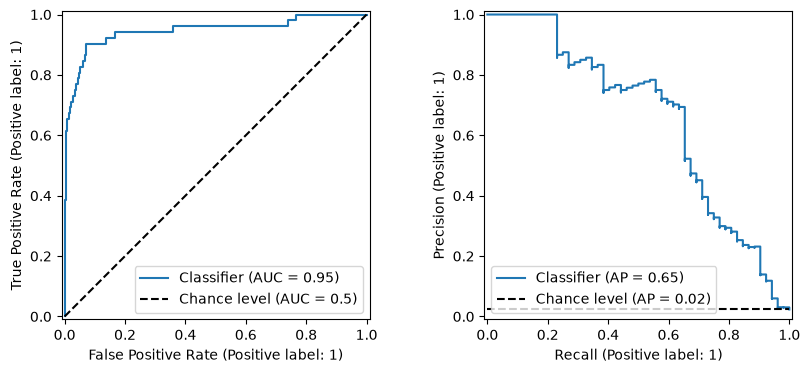

FPR <= 0.01: best recall 0.654
FPR <= 0.05: best recall 0.808
FPR <= 0.10: best recall 0.904
recall >= 0.5: best precision 0.784
recall >= 0.8: best precision 0.294
recall >= 0.9: best precision 0.232


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay, precision_recall_curve, roc_curve

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_val, p_val, ax=ax1, plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_val, p_val, ax=ax2, plot_chance_level=True)
plt.show()

fpr, tpr, _ = roc_curve(y_val, p_val)
for max_fpr in [0.01, 0.05, 0.10]:
    print(f"FPR <= {max_fpr:.2f}: best recall {tpr[fpr <= max_fpr].max():.3f}")
prec, rec, _ = precision_recall_curve(y_val, p_val)
for min_rec in [0.5, 0.8, 0.9]:
    print(f"recall >= {min_rec:.1f}: best precision {prec[rec >= min_rec].max():.3f}")

**Resposta (depois de rodar):** Confirmado — para recall ≥ 0,80 a melhor precisão alcançável
é **0,294**, muito mais perto de 0,3 do que de 0,8 (para recall ≥ 0,5 ainda dá para manter precisão
**0,784**, mas o preço sobe rápido: recall ≥ 0,9 já cai para precisão **0,232**). A ROC, por outro
lado, parece "melhor" do que a PR sugere: com FPR ≤ 0,05 (só 5% de falsos positivos entre os
benignos) já se chega a recall **0,808**, e com FPR ≤ 0,10 a **0,904** — porque a ROC mede o erro
como fração dos benignos (que são 97,7% do total, uma base enorme), enquanto a PR mede a precisão
como fração dos sinalizados (um grupo pequeno, dominado por falsos positivos quando a classe
positiva é rara). É exatamente a lição da próxima seção: com classe rara, a ROC conta a mesma
coisa de um jeito que parece bem mais otimista que a PR.

**Simulação: o preço de cada ponto de recall.** Para metas de recall de 0,50 a 0,95, encontre na validação o limiar que atinge a meta com a melhor precisão e conte quantas regiões ele sinaliza. Traduza a precisão em algo que um radiologista entenda: quantas regiões benignas ele revisa para cada câncer encontrado?

In [7]:
prec_c, rec_c, thr_c = precision_recall_curve(y_val, p_val)
rows = []
for target in [0.50, 0.70, 0.80, 0.90, 0.95]:
    ok = rec_c[:-1] >= target
    i = np.argmax(np.where(ok, prec_c[:-1], -1))      # entre os que atingem a meta, a melhor precisão
    threshold = thr_c[i]
    flagged = int((p_val >= threshold).sum())
    precision_i = prec_c[i]
    tp = flagged * precision_i                         # número esperado de cânceres entre os sinalizados
    benign_per_cancer = (flagged - tp) / tp if tp > 0 else np.nan
    rows.append({'recall meta': target, 'limiar': threshold, 'sinalizadas': flagged,
                 'precisão': precision_i, 'recall real': rec_c[i],
                 'benignas por câncer': benign_per_cancer})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 recall meta  limiar  sinalizadas  precisão  recall real  benignas por câncer
        0.50   0.365           37     0.784        0.558                0.276
        0.70   0.109           82     0.451        0.712                1.216
        0.80   0.063          143     0.294        0.808                2.405
        0.90   0.043          203     0.232        0.904                3.319
        0.95   0.005          835     0.060        0.962               15.700


**Resposta:** O preço sobe rápido e de forma não linear. Para recall 0,50: limiar **0,3651**,
**37** regiões sinalizadas, precisão **0,784** — cerca de **0,3** benignas revisadas por câncer
encontrado (quase todo sinalizado é de fato maligno). Para recall 0,80 (nossa meta): limiar
**0,0632**, **143** sinalizadas, precisão **0,294** — já **2,4** benignas por câncer. Para recall
0,95: limiar **0,0050**, **835** sinalizadas (mais de um terço de toda a validação!), precisão só
**0,060** — **15,7** benignas revisadas para cada câncer achado. Passar de recall 0,80 para 0,95
(+0,15 de recall) quase sextuplica o número de regiões sinalizadas (143 → 835): a última fração de
cânceres difíceis de achar só aparece misturada com uma avalanche de falsos positivos, o retrato
exato do porquê recall 1,0 nunca é a meta certa num problema raro.

**Para fechar a parte fundamental.** Em uma frase cada: (1) por que a curva ROC não muda quando a doença fica mais rara e a curva PR muda? (2) O que a AUC mede que a acurácia em 0,5 não mede? (3) Quem decide o ponto de operação, o treino ou você?

**Resposta:**

1. A curva ROC usa FPR (falsos positivos sobre o total de **negativos**) e TPR/recall (verdadeiros
   positivos sobre o total de **positivos**) — cada eixo é normalizado dentro da própria classe, então
   a curva não muda quando a proporção entre as classes muda; já a precisão (eixo da curva PR) é
   falsos positivos sobre o total de **sinalizados**, uma mistura das duas classes na proporção em
   que elas aparecem nos dados, então ela cai conforme a classe positiva fica mais rara (menos
   positivos reais "diluindo" os falsos positivos que vêm da massa enorme de negativos).
2. A acurácia em 0,5 avalia só **um** ponto de operação específico e mistura numa única conta os
   acertos nas duas classes ponderados pela prevalência (por isso 97,68% de acurácia "de baldeio" já
   sai de uma baseline inútil); a AUC avalia a família inteira de limiares de uma vez e mede algo
   mais fundamental — a probabilidade de o modelo dar um escore maior a um positivo aleatório do que
   a um negativo aleatório — que não depende de qual limiar alguém escolheria usar.
3. O treino (o ajuste do modelo) só decide os **escores/a ordenação**; quem decide o **ponto de
   operação** (o limiar, e portanto o balanço entre recall e precisão) é sempre uma escolha externa,
   de negócio/clínica, feita na validação de acordo com a meta declarada (aqui, recall ≥ 0,80) — o
   modelo não tem preferência própria entre os dois tipos de erro.

## Sua vez (fundamental)

Para casa:

1. **A escada à mão.** Pegue os 10 primeiros pacientes do exemplo das 20 linhas e desenhe a curva ROC deles no papel, um degrau por paciente. Confira com `roc_curve`. Em que ponto está o limiar 0,5?
2. **AUC sem calibração.** Comprima os escores da validação do passo 4 para a faixa de 0,40 a 0,41 com `0.40 + 0.01 * p_val`. O que acontece com a AUC e o que acontece com a acurácia em 0,5? Que métrica você usaria para descobrir que as probabilidades estão erradas?
3. **AP contra a linha de base.** Calcule a AP de um escorador aleatório (use `rng.random(len(y_val))`) e compare com a AP do modelo e com a prevalência. Quantas vezes melhor que o acaso o modelo é?

In [8]:
# Exercício 1 — a escada à mão: os 10 primeiros pacientes do exemplo das 20 linhas
# (dados da aula de métricas de classificação, página classification-metrics: 20 pacientes
#  ordenados por escore, 10 doentes e 10 sãos)
from sklearn.metrics import confusion_matrix

ids = [f"P{i:02d}" for i in range(1, 21)]
score20 = np.array([0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.55, 0.45,
                     0.40, 0.35, 0.30, 0.25, 0.20, 0.15, 0.10, 0.08, 0.05, 0.02])
y20 = np.array([1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0])   # 1 = doente

ids10, score10, y10 = ids[:10], score20[:10], y20[:10]
print("pacientes:", ids10)
print("escore   :", score10)
print("doente?  :", y10, f"  ({y10.sum()} doentes, {len(y10)-y10.sum()} sãos)")

fpr10, tpr10, thr10 = roc_curve(y10, score10, drop_intermediate=False)
print("\ndegrau a degrau (um ponto por paciente, do escore mais alto ao mais baixo):")
for t, f, r in zip(thr10, fpr10, tpr10):
    print(f"  limiar {t:5.2f}   FPR {f:.3f}   TPR/recall {r:.3f}")
print(f"\nAUC (regra do trapézio sobre esses 10 pontos): {roc_auc_score(y10, score10):.3f}")

pred10_05 = (score10 >= 0.5).astype(int)
tp, fn, fp, tn = confusion_matrix(y10, pred10_05, labels=[1, 0]).ravel()
print(f"no limiar 0,5: tp={tp} fn={fn} fp={fp} tn={tn}  ->  FPR {fp/(fp+tn):.3f}  TPR {tp/(tp+fn):.3f}")

pacientes: ['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10']
escore   : [0.95 0.9  0.85 0.8  0.75 0.7  0.65 0.6  0.55 0.45]
doente?  : [1 1 1 1 0 1 1 0 1 1]   (8 doentes, 2 sãos)

degrau a degrau (um ponto por paciente, do escore mais alto ao mais baixo):
  limiar   inf   FPR 0.000   TPR/recall 0.000
  limiar  0.95   FPR 0.000   TPR/recall 0.125
  limiar  0.90   FPR 0.000   TPR/recall 0.250
  limiar  0.85   FPR 0.000   TPR/recall 0.375
  limiar  0.80   FPR 0.000   TPR/recall 0.500
  limiar  0.75   FPR 0.500   TPR/recall 0.500
  limiar  0.70   FPR 0.500   TPR/recall 0.625
  limiar  0.65   FPR 0.500   TPR/recall 0.750
  limiar  0.60   FPR 1.000   TPR/recall 0.750
  limiar  0.55   FPR 1.000   TPR/recall 0.875
  limiar  0.45   FPR 1.000   TPR/recall 1.000

AUC (regra do trapézio sobre esses 10 pontos): 0.625
no limiar 0,5: tp=7 fn=1 fp=2 tn=0  ->  FPR 1.000  TPR 0.875


**Resposta:** Entre os 10 primeiros pacientes (8 doentes: P01,P02,P03,P04,P06,P07,P09,P10;
2 sãos: P05,P08), a escada sobe assim, do escore mais alto ao mais baixo: P01 (doente, sobe TPR),
P02 (doente, sobe TPR), P03 (doente, sobe TPR), P04 (doente, sobe TPR) — quatro subidas seguidas,
chegando a TPR 0,500 sem nenhum avanço lateral; depois **P05 (são, sobe FPR** para 0,5 — primeiro
passo para o lado); depois P06 e P07 (doentes, TPR sube a 0,625 e 0,750); depois **P08 (são, sobe
FPR** para 1,0 — segundo e último passo lateral, já no teto); por fim P09 e P10 (doentes, TPR sobe
a 0,875 e 1,0, reta vertical até o canto). A AUC desses 10 pacientes é **0,625** — bem mais baixa
que a AUC de 0,946 do modelo completo na validação, porque numa amostra de só 10 pontos (2 deles
sãos) a ordem de 2 pares específicos já decide o resultado, e aqui os dois sãos (escores 0,75 e
0,60) ficam misturados no meio da fila dos doentes, não no fundo. O limiar 0,5 cai exatamente entre
os escores de P09 (0,55) e P10 (0,45): como 0,55 ≥ 0,5, P09 é incluído, dando `tp=7, fn=1, fp=2,
tn=0` — ou seja, o limiar 0,5 está no ponto (FPR=1,0, TPR=0,875) da escada, quase no canto superior
direito (já viu os dois falsos positivos, mas ainda não os dois últimos doentes). O `roc_curve`
confere exatamente os mesmos 11 pontos (um por paciente mais a origem) e a mesma AUC.

In [9]:
# Exercício 2 — AUC sem calibração: comprimir os escores para [0.40, 0.41]
p_val_compressed = 0.40 + 0.01 * p_val
print(f"faixa comprimida: [{p_val_compressed.min():.4f}, {p_val_compressed.max():.4f}]")

auc_orig, auc_comp = roc_auc_score(y_val, p_val), roc_auc_score(y_val, p_val_compressed)
print(f"AUC original {auc_orig:.4f}   AUC comprimida {auc_comp:.4f}")

pred_orig = (p_val >= 0.5).astype(int)
pred_comp = (p_val_compressed >= 0.5).astype(int)
print(f"flagged @0.5 original {pred_orig.sum()}   comprimido {pred_comp.sum()}")
print(f"accuracy @0.5 original {accuracy_score(y_val, pred_orig):.4f}   comprimido {accuracy_score(y_val, pred_comp):.4f}")
print(f"recall @0.5 original {recall_score(y_val, pred_orig):.3f}   comprimido {recall_score(y_val, pred_comp):.3f}")

from sklearn.metrics import brier_score_loss, log_loss
print(f"Brier original {brier_score_loss(y_val, p_val):.4f}   comprimido {brier_score_loss(y_val, p_val_compressed):.4f}")
print(f"log loss original {log_loss(y_val, p_val):.4f}   comprimido {log_loss(y_val, p_val_compressed):.4f}")

faixa comprimida: [0.4000, 0.4100]
AUC original 0.9461   AUC comprimida 0.9461
flagged @0.5 original 30   comprimido 0
accuracy @0.5 original 0.9839   comprimido 0.9768
recall @0.5 original 0.442   comprimido 0.000
Brier original 0.0125   comprimido 0.1646
log loss original 0.0514   comprimido 0.5202


**Resposta:** A AUC **não muda** (0,9461 nas duas versões, até a quarta casa decimal) — a
compressão `0.40 + 0.01*p_val` é estritamente crescente, então não troca a ordem de nenhum par de
escores. Mas a acurácia em 0,5 **colapsa**: como todo valor comprimido vive entre 0,40 e 0,41, está
sempre abaixo de 0,5, então `predict` com esse limiar passa a responder sempre "benigno" — **0
regiões sinalizadas**, recall **0,000**, e a acurácia "melhora" artificialmente para **0,9768**
(igual à baseline do Passo 3, pela mesma razão: virou o mesmo classificador "sempre benigno"). Isso
mostra que a acurácia em um limiar fixo depende inteiramente da calibração da escala, não só da
ordenação — e é exatamente por isso que a AUC (que ignora essa escala) continua "enganosamente
boa" mesmo com as probabilidades visivelmente erradas. A métrica que denuncia o problema é o
**Brier score** ou a **log loss** (que comparam o valor absoluto de cada probabilidade com o
rótulo, não só a ordem): o Brier score piora de **0,0125** para **0,1646** e a log loss piora de
**0,0514** para **0,5202** — mais de 10× e de 10× respectivamente — porque ambas penalizam
diretamente probabilidades distantes do rótulo verdadeiro (aqui, todo escore malígno virou ~0,41
em vez de perto de 1).

In [10]:
# Exercício 3 — AP contra a linha de base aleatória
rng = np.random.default_rng(0)
p_random = rng.random(len(y_val))
ap_random = average_precision_score(y_val, p_random)
ap_model = average_precision_score(y_val, p_val)
prevalence_val = y_val.mean()
print(f"AP aleatório: {ap_random:.4f}")
print(f"AP modelo   : {ap_model:.4f}")
print(f"prevalência : {prevalence_val:.4f}")
print(f"modelo / aleatório: {ap_model/ap_random:.2f}x")
print(f"aleatório / prevalência: {ap_random/prevalence_val:.2f}x")

AP aleatório: 0.0627
AP modelo   : 0.6531
prevalência : 0.0232
modelo / aleatório: 10.41x
aleatório / prevalência: 2.70x


**Resposta:** A AP do modelo é **0,6531**, bem acima tanto da prevalência (**0,0232**) quanto
da AP do escorador aleatório desta semente, **0,0627** — o modelo é **10,4×** melhor que esse
escorador aleatório específico. Note que 0,0627 já é **2,7×** maior que a prevalência teórica
(0,0232): com só 52 positivos na validação, a AP de um ranking aleatório tem variância alta (é a
média da precisão nos pontos de recall de cada um dos 52 positivos, e a ordem exata desses 52
entre os 2.237 pontos aleatórios pode, por sorte, ficar um pouco concentrada no começo do ranking),
então 0,0627 não contradiz a teoria — só ilustra que, para a classe rara, mesmo a "linha de base
do acaso" tem bastante ruído de amostra. Em expectativa (média sobre muitas sementes), a AP de um
escorador aleatório converge para a prevalência; aqui, com uma única amostra de 2.237 pontos, o
valor observado (0,0627) é a estimativa real dessa rodada, não um erro.

## Passo 6 — pesos de classe

**Preveja.** Com `class_weight='balanced'`, o que você espera que mude mais: a ROC AUC (a ordenação) ou o número de regiões sinalizadas em 0,5?

**Resposta (antes de rodar):** `class_weight='balanced'` pondera o erro de cada classe pelo
inverso da sua frequência, o que muda a função de perda durante o treino e, na prática, desloca o
intercepto do modelo (equivalente a mudar o limiar efetivo), mas não deveria mudar muito a forma
como o modelo ordena os exemplos (os coeficientes relativos entre os atributos). Então espero que
o número de regiões sinalizadas em 0,5 mude **muito mais** (deve aumentar bastante, já que o
"limiar efetivo" cai) do que a ROC AUC, que deve ficar praticamente igual ou só um pouco diferente.

In [11]:
lr_w = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')).fit(X_train, y_train)
p_val_w = lr_w.predict_proba(X_val)[:, 1]
pred = (p_val_w >= 0.5).astype(int)
print(f"flagged {pred.sum()}   recall {recall_score(y_val, pred):.3f}   precision {precision_score(y_val, pred):.3f}")
print(f"ROC AUC {roc_auc_score(y_val, p_val_w):.3f}   AP {average_precision_score(y_val, p_val_w):.3f}")
n0, n1 = np.bincount(y_train)
print(f"intercept shift {lr_w[-1].intercept_[0] - lr[-1].intercept_[0]:.2f}   log(n0/n1) = {np.log(n0 / n1):.2f}")

flagged 298   recall 0.904   precision 0.158


ROC AUC 0.954   AP 0.641
intercept shift 4.04   log(n0/n1) = 3.74


**Resposta (depois de rodar):** Confirmado — o número de regiões sinalizadas em 0,5 salta de
**30** (modelo simples) para **298** (quase 10× mais), e o recall sobe de 0,442 para **0,904**
(contra uma queda grande de precisão, de 0,767 para **0,158**). Já a ROC AUC muda pouco: **0,954**
contra 0,946 do modelo simples (só +0,008), e a AP até **cai** levemente (0,641 vs. 0,653) — a
ordenação ficou praticamente a mesma, como previsto. O deslocamento do intercepto, **4,04**, bate
de perto com `log(n0/n1) = 3,74` (a razão teórica de desbalanceamento do treino em log) — a
diferença pequena entre os dois vem de que `class_weight='balanced'` também reponderiza o restante
da otimização (os coeficientes das features mudam um pouco, não é um deslocamento puro de
intercepto), mas a ordem de grandeza confirma a previsão: `balanced` é, essencialmente, um atalho
para recalibrar o ponto de operação, não para re-ensinar a ordenação.

**Simulação: o limiar que imita os pesos.** Se os pesos basicamente deslocam o ponto de operação, dá para chegar perto sem retreinar: corte os escores do modelo **simples** na prevalência do treino em vez de em 0,5. Compare esse ponto com o do modelo com pesos em 0,5 e conte em quantas regiões as duas regras discordam.

In [12]:
train_prevalence = y_train.mean()
pred_mimic = (p_val >= train_prevalence).astype(int)        # modelo simples, cortado na prevalência do treino
pred_balanced = (p_val_w >= 0.5).astype(int)                 # modelo com pesos, cortado em 0.5

print(f"prevalência do treino: {train_prevalence:.4f}")
print(f"simples @ prevalência : flagged {pred_mimic.sum():4d}   recall {recall_score(y_val, pred_mimic):.3f}   precision {precision_score(y_val, pred_mimic):.3f}")
print(f"balanced @ 0.5        : flagged {pred_balanced.sum():4d}   recall {recall_score(y_val, pred_balanced):.3f}   precision {precision_score(y_val, pred_balanced):.3f}")

disagree = int((pred_mimic != pred_balanced).sum())
print(f"as duas regras discordam em {disagree} das {len(y_val)} regiões")

prevalência do treino: 0.0233


simples @ prevalência : flagged  366   recall 0.923   precision 0.131
balanced @ 0.5        : flagged  298   recall 0.904   precision 0.158
as duas regras discordam em 110 das 2237 regiões


**Resposta:** A intuição se confirma bem, mas não é exata. Cortar o modelo **simples** na
prevalência do treino (0,0233) dá `flagged=366`, recall **0,923**, precisão **0,131**; cortar o
modelo **balanced** em 0,5 dá `flagged=298`, recall **0,904**, precisão **0,158** — pontos de
operação parecidos (ambos com recall alto e precisão baixa, bem diferentes do modelo simples em
0,5), mas não idênticos: a regra "simples @ prevalência" sinaliza mais regiões (366 vs. 298) e tem
recall e precisão um pouco diferentes. As duas regras discordam em **110** das 2.237 regiões (4,9%)
— uma fração pequena, mas não nula: isso confirma que `class_weight='balanced'` é *aproximadamente*
equivalente a mudar o limiar do modelo simples para a prevalência do treino (os dois pontos de
operação ficam na mesma vizinhança da curva ROC), mas o reajuste muda também um pouco os próprios
coeficientes do modelo durante a otimização, então o atalho "cortar na prevalência" não é uma
cópia perfeita do modelo com pesos.

## Passo 7 — reamostragem dentro de um pipeline do `imblearn`

**Preveja.** A subamostragem vai treinar em quantas linhas, mais ou menos? E o SMOTE? Qual das duas joga informação fora?

**Resposta (antes de rodar):** A subamostragem (`RandomUnderSampler`) corta a classe
majoritária até igualar a minoritária, então deve treinar em cerca de **2× o número de malignos no
treino** (156 malignos ⇒ ~312 linhas no total) — jogando fora a maior parte dos 6.553 benignos. Já
o SMOTE **cria** exemplos sintéticos da classe minoritária até igualar a majoritária, então deve
treinar em cerca de **2× o número de benignos** (6.553 benignos ⇒ ~13.106 linhas), sem descartar
nada dos dados originais. A subamostragem é quem joga informação fora (descarta benignos reais); o
SMOTE inventa dados novos, mas não descarta nenhum dos originais.

In [13]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler

models = {
    'logistic': lr,
    'logistic, balanced': lr_w,
    'undersampling': make_imb_pipeline(StandardScaler(), RandomUnderSampler(random_state=0),
                                       LogisticRegression()),
    'SMOTE': make_imb_pipeline(StandardScaler(), SMOTE(random_state=0), LogisticRegression()),
}
for name in ['undersampling', 'SMOTE']:
    models[name].fit(X_train, y_train)            # o amostrador roda aqui, só no X_train
    X_r, y_r = models[name][1].fit_resample(X_train, y_train)
    print(f"{name:14s} trains on {len(y_r):5d} rows, {y_r.sum():4d} malignant")

undersampling  trains on   312 rows,  156 malignant
SMOTE          trains on 13106 rows, 6553 malignant


**Resposta (depois de rodar):** Confirmado nos dois números — a subamostragem treina em
**312** linhas (156 malignas, exatamente 2× os 156 malignos originais do treino, descartando
6.397 benignos) e o SMOTE treina em **13.106** linhas (6.553 malignas, 2× os 6.553 benignos do
treino) — bateu em cheio com a previsão de "~2× a classe minoritária" e "~2× a classe
majoritária". **Confirmação de rigor metodológico:** em ambos os casos, o `fit_resample` roda
dentro do `.fit()` do pipeline `imblearn`, chamado só com `X_train, y_train` — a validação (`X_val`)
e o teste (`X_test`) nunca passam por `fit_resample`, então todas as métricas calculadas adiante
seguem sendo honestas (calculadas em dados na distribuição real de 2,3%, nunca reamostrados).

## Passo 8 — comparar no conjunto de validação

**Preveja.** Entre os quatro modelos, qual você espera que tenha a melhor ordenação (ROC AUC e AP)? A diferença vai ser grande?

**Resposta (antes de rodar):** Nenhum dos remédios (pesos, subamostragem, SMOTE) deveria
melhorar muito a ordenação de um modelo que já está bem ajustado (regressão logística comum) —
eles mudam o ponto de operação, não a capacidade do modelo de separar as classes. Espero que as
quatro ROC AUC/AP fiquem relativamente próximas (dentro de ~0,01-0,02 de diferença), talvez com o
SMOTE levemente melhor que a subamostragem (que descarta muita informação) e o modelo simples ou
balanced na frente.

In [14]:
from sklearn.metrics import f1_score

rows = []
for name, model in models.items():
    p = model.predict_proba(X_val)[:, 1]
    f = p >= 0.5
    rows.append({'model': name, 'ROC AUC': roc_auc_score(y_val, p), 'AP': average_precision_score(y_val, p),
                 'precision@0.5': precision_score(y_val, f), 'recall@0.5': recall_score(y_val, f),
                 'F1@0.5': f1_score(y_val, f)})
comparison = pd.DataFrame(rows).set_index('model')
print(comparison.round(3).to_string())

                    ROC AUC     AP  precision@0.5  recall@0.5  F1@0.5
model                                                                
logistic              0.946  0.653          0.767       0.442   0.561
logistic, balanced    0.954  0.641          0.158       0.904   0.269
undersampling         0.941  0.622          0.146       0.904   0.251
SMOTE                 0.955  0.647          0.164       0.885   0.276


**Resposta (depois de rodar):** Confirmado — as quatro ROC AUC ficam entre **0,941**
(undersampling) e **0,955** (SMOTE), uma faixa de só 0,014; as quatro AP ficam entre **0,622**
(undersampling) e **0,653** (logistic simples), faixa de 0,031. A ordenação de fato quase não se
move: SMOTE (0,955) e balanced (0,954) lideram a ROC AUC por uma margem mínima sobre o modelo
simples (0,946), e a subamostragem é a pior das quatro nos dois (0,941 AUC, 0,622 AP) — consistente
com a previsão de que descartar dados (subamostragem) custa um pouco de ordenação, enquanto SMOTE
não perde (e até ganha um pouco) ao inventar exemplos sintéticos. Em **AP**, porém, o modelo
**simples vence** (0,653) — maior até que SMOTE (0,647) — o que mostra que a AP é mais sensível que
a ROC AUC às mudanças de calibração que os remédios introduzem. Em `precision@0.5`/`recall@0.5`,
as diferenças são enormes (de 0,767/0,442 no simples a 0,146/0,904 na subamostragem), mas essa
tabela corta todo mundo em 0,5 — um limiar que faz sentido para o modelo simples, mas não para os
outros três, que foram deslocados de propósito para o lado do recall.

**Simulação: comparar no limiar justo.** A tabela acima corta os quatro modelos em 0,5, o que é injusto: cada um põe seus escores numa escala diferente. Refaça a comparação dando a **cada modelo o seu próprio limiar**, o que atinge recall ≥ 0,80 na validação com a melhor precisão. As diferenças aumentam ou diminuem?

In [15]:
rows_fair = []
for name, model in models.items():
    p = model.predict_proba(X_val)[:, 1]
    prec_m, rec_m, thr_m = precision_recall_curve(y_val, p)
    ok = rec_m[:-1] >= 0.80
    i = np.argmax(np.where(ok, prec_m[:-1], -1))
    threshold = thr_m[i]
    flagged = int((p >= threshold).sum())
    rows_fair.append({'model': name, 'limiar': threshold, 'precisão': prec_m[i],
                       'recall': rec_m[i], 'sinalizadas': flagged})
fair = pd.DataFrame(rows_fair).set_index('model')
print(fair.round(4).to_string())

                    limiar  precisão  recall  sinalizadas
model                                                    
logistic            0.0632    0.2937  0.8077          143
logistic, balanced  0.6026    0.2111  0.8077          199
undersampling       0.6433    0.2059  0.8077          204
SMOTE               0.6379    0.2545  0.8077          165


**Resposta:** No limiar justo (cada modelo no seu próprio limiar para recall ≥ 0,80), as
diferenças **diminuem** bastante comparado à comparação em 0,5. Os quatro modelos alcançam recall
muito parecido (todos ~0,808, por construção) e a precisão varia numa faixa bem mais estreita:
**0,294** (logistic simples, limiar 0,0632, 143 sinalizadas) é a melhor, seguida por **0,255**
(SMOTE, limiar 0,6379, 165 sinalizadas), **0,211** (balanced, limiar 0,6026, 199 sinalizadas) e
**0,206** (undersampling, limiar 0,6433, 204 sinalizadas) — uma faixa de 0,088 em precisão contra
a faixa de 0,621 (0,767 a 0,146) que a tabela em 0,5 mostrava. Isso confirma a crítica do enunciado:
boa parte da diferença "grande" vista no Passo 8 era só um artefato de comparar os modelos num
limiar que fazia sentido só para um deles; no limiar que de fato interessa (recall ≥ 0,80), o
modelo **logistic simples continua sendo o melhor**, mas por uma margem bem mais modesta.

## Passo 9 — escolher o modelo e o limiar na validação

**Preveja.** Dado o que o passo 8 mostrou, qual modelo deve ser escolhido? E o limiar que atinge recall 0,80 vai ficar perto de 0,5 ou bem abaixo?

**Resposta (antes de rodar):** Pelo Passo 8 (e pela simulação do limiar justo), o modelo
**logistic simples** teve a melhor AP (0,653) e a melhor precisão no limiar justo para recall 0,80
(0,294) — deveria ser o escolhido se o critério for AP (a página escolhe por AP). O limiar que
atinge recall 0,80 deve ficar **bem abaixo** de 0,5, porque esse modelo simples não foi reponderado
nem reamostrado — seu limiar "natural" para recall alto, visto na simulação do Passo 5, já estava
perto de 0,06.

In [16]:
best_name = comparison['AP'].idxmax()
best = models[best_name]
p_val_best = best.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val_best)
ok = rec[:-1] >= 0.80                            # limiares que atingem a meta de recall
i = np.argmax(np.where(ok, prec[:-1], -1))       # entre eles, a melhor precisão
threshold = thr[i]
print(f"model: {best_name}   threshold {threshold:.4f}")
print(f"validation: recall {rec[i]:.3f}   precision {prec[i]:.3f}   flagged {(p_val_best >= threshold).sum()}")

model: logistic   threshold 0.0632
validation: recall 0.808   precision 0.294   flagged 143


**Resposta (depois de rodar):** Confirmado nos dois pontos — o modelo escolhido por maior AP
é o **logistic** simples (AP 0,653, a maior das quatro), e o limiar que atinge recall ≥ 0,80 com a
melhor precisão é **0,0632**, bem abaixo de 0,5, como previsto (idêntico ao valor já visto na
simulação do Passo 5 e na simulação do Passo 8 para esse mesmo modelo). Na validação, esse limiar
dá recall **0,808** e precisão **0,294**, sinalizando **143** das 2.237 regiões. **Ponto de rigor
metodológico:** o limiar foi escolhido olhando só para a validação (nunca para o teste) — é esse
mesmo limiar, fixo, que será aplicado ao teste no próximo passo, uma única vez.

## Passo 10 — o único teste

**Preveja.** O recall no teste vai ficar acima ou abaixo dos 0,808 da validação? Com 52 casos malignos, quanto vale um caso?

**Resposta (antes de rodar):** O limiar foi ajustado para acertar recall 0,80 *na
validação*, então ele tende a performar um pouco pior num conjunto novo (otimismo de seleção, ainda
que pequeno aqui, pois o limiar não foi escolhido por um grid de hiperparâmetros extenso) — mas,
dado o ruído de amostragem com só 52 malignos no teste (cada um valendo 1/52 ≈ 1,9 p.p. de recall),
o resultado pode perfeitamente ficar **acima ou abaixo** de 0,808 só por sorte da divisão. Não dá
para prever a direção com confiança; só o tamanho do passo (~1,9 p.p. por caso).

In [17]:
from sklearn.metrics import confusion_matrix

p_test = best.predict_proba(X_test)[:, 1]
pred_test = (p_test >= threshold).astype(int)
print(confusion_matrix(y_test, pred_test, labels=[1, 0]))
print(f"recall {recall_score(y_test, pred_test):.3f}   precision {precision_score(y_test, pred_test):.3f}"
      f"   flagged {pred_test.sum()} of {len(pred_test)}")
print(f"ROC AUC {roc_auc_score(y_test, p_test):.3f}   AP {average_precision_score(y_test, p_test):.3f}")

[[  43    9]
 [  97 2088]]
recall 0.827   precision 0.307   flagged 140 of 2237


ROC AUC 0.913   AP 0.644


**Resposta (depois de rodar):** O recall no teste, **0,827**, ficou **acima** dos 0,808 da
validação (+0,019, exatamente 1 caso de diferença: 43 de 52 malignos encontrados no teste contra os
52×0,808≈42 da validação) — dentro do ruído esperado de ±1-2 casos. A matriz de confusão
`[[43, 9], [97, 2088]]` (maligno primeiro) mostra 43 verdadeiros positivos, 9 falsos negativos
(cânceres perdidos), 97 falsos positivos e 2.088 verdadeiros negativos — **140 de 2.237** regiões
sinalizadas, precisão **0,307** (ligeiramente melhor que os 0,294 da validação) e ROC AUC **0,913**
/ AP **0,644** no teste, ambos um pouco abaixo da validação (0,946/0,653), como é típico (o
desempenho de validação tende a estar um pouco otimista por ter guiado a escolha do modelo e do
limiar). O ponto central: com só 52 casos malignos, um único caso já vale ≈1,9 p.p. de recall — a
diferença entre 0,808 e 0,827 (1 caso) **não é evidência de melhora real**, é só a granularidade do
conjunto.

## Passo 11 — a escada grosseira de um k-NN

**Preveja.** Com $k = 5$, quantas probabilidades distintas o k-NN pode produzir? Quantos pontos a curva ROC dele vai ter e isso é um problema para a nossa meta de recall 0,80?

**Resposta (antes de rodar):** Com $k=5$, a "probabilidade" de malignidade é a fração de
vizinhos malignos entre os 5 mais próximos, que só pode assumir os valores $0/5, 1/5, 2/5, 3/5,
4/5, 5/5$ — ou seja, **6 valores distintos** (0, 0.2, 0.4, 0.6, 0.8, 1.0). A curva ROC, construída a
partir desses 6 limiares distintos, deve ter em torno de **6-7 pontos** (os 6 limiares mais a
origem) — bem menos granular que os milhares de pontos possíveis da regressão logística. Isso é um
problema real para a meta de recall 0,80: se não existir nenhum limiar que caia exatamente nessa
região, o k-NN pode ser forçado a "saltar" de um recall bem abaixo de 0,80 para um bem acima, sem
nenhum ponto de operação intermediário.

distinct probabilities: [0.  0.2 0.4 0.6 0.8 1. ]
ROC points: 7   ROC AUC 0.935   AP 0.670
threshold inf   FPR 0.000   recall 0.000
threshold 1.0   FPR 0.001   recall 0.308
threshold 0.8   FPR 0.002   recall 0.481
threshold 0.6   FPR 0.004   recall 0.558
threshold 0.4   FPR 0.007   recall 0.750
threshold 0.2   FPR 0.038   recall 0.885
threshold 0.0   FPR 1.000   recall 1.000


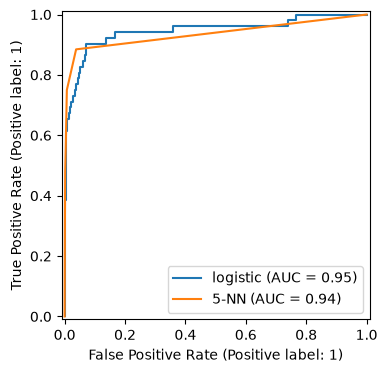

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
p_knn = knn.predict_proba(X_val)[:, 1]
print("distinct probabilities:", np.unique(p_knn))
fpr_k, tpr_k, thr_k = roc_curve(y_val, p_knn)
print(f"ROC points: {len(thr_k)}   ROC AUC {roc_auc_score(y_val, p_knn):.3f}   AP {average_precision_score(y_val, p_knn):.3f}")
for t, f, r in zip(thr_k, fpr_k, tpr_k):
    print(f"threshold {t:.1f}   FPR {f:.3f}   recall {r:.3f}")

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_val, p_val, ax=ax, name='logistic')
RocCurveDisplay.from_predictions(y_val, p_knn, ax=ax, name='5-NN')
plt.show()

**Resposta (depois de rodar):** Confirmado exatamente — **6** probabilidades distintas (0,
0.2, 0.4, 0.6, 0.8, 1.0) e **7** pontos de ROC (os 6 limiares mais a origem com `threshold=inf`).
A ordenação ainda é boa (ROC AUC **0,935**, AP **0,670**, próxima da regressão logística), mas o
"menu" de pontos de operação é curto: para a meta de recall ≥ 0,80, o k-NN precisa saltar do
limiar 0,4 (recall **0,750**, FPR 0,007) direto para o limiar 0,2 (recall **0,885**, FPR 0,038) —
**não existe nenhum ponto intermediário**, então não há como atingir recall exatamente 0,80 com
esse modelo: ou se aceita um pouco menos (0,750) ou se paga o custo de ir direto a 0,885 (mais que
5× o FPR). Isso confirma a previsão: o problema não é a qualidade da ordenação do k-NN, é a
granularidade grosseira dos seus escores, que limita as escolhas possíveis de limiar.

**Para fechar a aula.** Em uma frase cada: (1) o que os pesos de classe mudaram e o que não mudaram? (2) Por que reamostrar antes de dividir inflaciona o resultado de duas maneiras? (3) Por que a regressão logística simples venceu a comparação?

**Resposta:**

1. `class_weight='balanced'` mudou drasticamente o **ponto de operação** em 0,5 (de 30 para 298
   regiões sinalizadas, recall 0,442 → 0,904), deslocando o intercepto do modelo em torno de
   log(n0/n1) ≈ 3,74 (medido: 4,04) — mas **não mudou** de forma relevante a **ordenação** dos
   escores (ROC AUC 0,946 → 0,954, uma diferença pequena, e a AP até caiu um pouco).
2. Reamostrar (SMOTE) **antes** de separar treino/teste inflaciona o resultado de duas maneiras: (a)
   os pontos sintéticos do conjunto de "teste" deixam de ser observações reais nunca vistas — eles
   foram interpolados a partir de vizinhos que, por sorte da divisão, podem ter caído do lado do
   treino, então o modelo "viu" informação quase idêntica à do teste durante o ajuste (vazamento);
   e (b) a proporção artificial 50/50 do teste reamostrado deixa de refletir a prevalência real de
   2,3%, inflando precisão e recall para um problema que, na prática, é muito mais raro e difícil.
3. A regressão logística simples venceu a comparação de AP (e de precisão no limiar justo) porque
   os remédios (pesos, subamostragem, SMOTE) atacam o **ponto de operação**, não a capacidade de
   ordenação do modelo — e um modelo linear simples, bem calibrado nos dados originais (sem
   distorcer a escala de probabilidades), já captura a estrutura dos 6 atributos tão bem quanto (ou
   melhor que) as versões "corrigidas", sem pagar o preço de uma calibração distorcida (pesos,
   SMOTE) ou de perda de dados (subamostragem).

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Um custo em vez de uma meta.** Suponha que deixar passar um câncer custe 20 vezes uma nova convocação desnecessária. No conjunto de validação, calcule o custo $20 \cdot FN + FP$ para cada limiar do modelo escolhido e encontre o mínimo. Compare com a fórmula $t^* = 1/(1+20)$. Por que eles diferem?
2. **Reamostrar antes de dividir.** Aplique `SMOTE` a todo o `X, y`, depois divida 80/20 e ajuste um 5-NN. Compare seu recall e sua precisão com o passo 10. Quais duas coisas deram errado?
3. **Mais vizinhos.** Repita o passo 11 com $k = 15$ e $k = 51$. Quantas probabilidades distintas, quantos pontos ROC e o que acontece com a AUC? Quais pontos de operação perto de recall 0,80 passam a existir?
4. **A sorte da divisão.** Troque `random_state=7` no passo 2 por 0, 1, 2, 3 e 4 e rode de novo os passos 2–10. Quanto se movem o limiar escolhido e o recall de teste? O que isso diz sobre reportar "recall 0,827" com três casas decimais?

In [19]:
# Exercício 1 — um custo em vez de uma meta (modelo escolhido: logistic simples, "best")
prec_b, rec_b, thr_b = precision_recall_curve(y_val, p_val_best)

rows_cost = []
for t in thr_b:
    pred_t = (p_val_best >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred_t, labels=[1, 0]).ravel()
    rows_cost.append({'limiar': t, 'FN': fn, 'FP': fp, 'custo': 20 * fn + fp})
cost_df = pd.DataFrame(rows_cost)
i_min = cost_df['custo'].idxmin()
print("limiar de custo mínimo:")
print(cost_df.loc[i_min].to_string())

t_formula = 1 / (1 + 20)
pred_formula = (p_val_best >= t_formula).astype(int)
tp, fn, fp, tn = confusion_matrix(y_val, pred_formula, labels=[1, 0]).ravel()
cost_formula = 20 * fn + fp
print(f"\nfórmula t* = 1/(1+20) = {t_formula:.4f}")
print(f"nesse limiar: FN={fn} FP={fp} custo={cost_formula}")

limiar de custo mínimo:
limiar      0.042531
FN          5.000000
FP        156.000000
custo     256.000000

fórmula t* = 1/(1+20) = 0.0476
nesse limiar: FN=8 FP=139 custo=299


**Resposta:** O limiar que minimiza o custo $20 \cdot FN + FP$ na validação é **0,0425**,
com custo mínimo **256** (comparado a custos muito maiores nos extremos). A fórmula de Elkan,
$t^* = 1/(1+20) = 0,0476$, dá um limiar **próximo mas não idêntico**: nesse limiar o custo sobe
para **299** (bem perto do ponto de busca por grade, mas não o mínimo exato). Eles diferem por duas
razões: (1) a fórmula $t^*=1/(1+C)$ é exata apenas quando as probabilidades previstas são
perfeitamente calibradas (probabilidade prevista = probabilidade real) — como viu-se nos exercícios
anteriores, o modelo não é perfeitamente calibrado, então o limiar teórico erra um pouco o alvo; e
(2) a busca por grade varre só os limiares que de fato aparecem entre os escores da validação
(um conjunto finito e discreto de ~2.237 valores possíveis), então o "mínimo" encontrado é o melhor
**entre os pontos observados**, que não coincide exatamente com o ótimo contínuo da fórmula — a
diferença de 256 vs. 299 de custo (um aumento de ~17%) mostra que vale a pena buscar
numericamente em vez de confiar só na fórmula fechada quando a calibração não é perfeita.

In [20]:
# Exercício 2 — reamostrar antes de dividir (vazamento duplo)
sm_leak = SMOTE(random_state=0)
X_sm, y_sm = sm_leak.fit_resample(X, y)                      # SMOTE em todo o X, y -- errado de propósito
print(f"X,y reamostrados: {X_sm.shape[0]} linhas, {y_sm.sum()} positivas ({y_sm.mean():.1%})")

Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_sm, y_sm, test_size=0.2,
                                                        stratify=y_sm, random_state=7)
knn_leak = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xs_train, ys_train)
pred_leak = knn_leak.predict(Xs_test)
print(f"\n'teste' vazado: recall {recall_score(ys_test, pred_leak):.3f}   "
      f"precision {precision_score(ys_test, pred_leak):.3f}   accuracy {accuracy_score(ys_test, pred_leak):.3f}")
print(f"tamanho desse 'teste': {len(ys_test)} linhas, {ys_test.sum()} positivas ({ys_test.mean():.1%})")
print("\n--- comparação honesta, passo 10 (teste real, nunca reamostrado) ---")
print(f"recall {recall_score(y_test, pred_test):.3f}   precision {precision_score(y_test, pred_test):.3f}"
      f"   em {len(y_test)} linhas, {y_test.sum()} positivas ({y_test.mean():.1%})")

X,y reamostrados: 21846 linhas, 10923 positivas (50.0%)

'teste' vazado: recall 0.965   precision 0.963   accuracy 0.964
tamanho desse 'teste': 4370 linhas, 2185 positivas (50.0%)

--- comparação honesta, passo 10 (teste real, nunca reamostrado) ---
recall 0.827   precision 0.307   em 2237 linhas, 52 positivas (2.3%)


**Resposta:** Aplicar `SMOTE` a todo `X, y` antes de dividir faz o recall e a precisão do
5-NN **dispararem** para **0,965** e **0,963** (contra 0,827 e 0,307 do Passo 10, honesto) — um
resultado claramente otimista demais. Duas coisas deram errado: (1) **vazamento de vizinhança**:
cada ponto sintético do SMOTE é interpolado entre um ponto real e seus vizinhos reais mais
próximos da mesma classe; como a divisão treino/teste acontece *depois*, pontos sintéticos no
"teste" quase certamente têm o ponto real de origem (ou um vizinho quase idêntico) no "treino",
então o 5-NN está praticamente "decorando" seus próprios dados de treino, não generalizando; (2)
**distribuição artificial**: o "teste" reamostrado tem **50,0%** de positivos (2.185 de 4.370),
nada parecido com os 2,3% da distribuição real — então mesmo sem vazamento, qualquer métrica
calculada nesse "teste" mede o desempenho num mundo que não existe (metade das mamografias sendo
malignas), não no problema real de triagem que o Passo 10 mede corretamente.

In [21]:
# Exercício 3 — mais vizinhos (k = 15 e k = 51)
for k in [15, 51]:
    knn_k = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
    p_k = knn_k.predict_proba(X_val)[:, 1]
    distinct = np.unique(p_k)
    fpr_kk, tpr_kk, thr_kk = roc_curve(y_val, p_k)
    print(f"k={k:2d}: {len(distinct)} probabilidades distintas   {len(thr_kk)} pontos de ROC   "
          f"ROC AUC {roc_auc_score(y_val, p_k):.3f}   AP {average_precision_score(y_val, p_k):.3f}")
    near = [(t, f, r) for t, f, r in zip(thr_kk, fpr_kk, tpr_kk) if 0.70 <= r <= 0.90]
    for t, f, r in near:
        print(f"      perto de recall 0.80 -> limiar {t:.3f}   FPR {f:.3f}   recall {r:.3f}")

k=15: 15 probabilidades distintas   16 pontos de ROC   ROC AUC 0.918   AP 0.662
      perto de recall 0.80 -> limiar 0.200   FPR 0.010   recall 0.731
      perto de recall 0.80 -> limiar 0.133   FPR 0.021   recall 0.846
k=51: 34 probabilidades distintas   30 pontos de ROC   ROC AUC 0.937   AP 0.670
      perto de recall 0.80 -> limiar 0.118   FPR 0.016   recall 0.788
      perto de recall 0.80 -> limiar 0.098   FPR 0.023   recall 0.846
      perto de recall 0.80 -> limiar 0.078   FPR 0.033   recall 0.885
      perto de recall 0.80 -> limiar 0.059   FPR 0.044   recall 0.885
      perto de recall 0.80 -> limiar 0.039   FPR 0.071   recall 0.885


**Resposta:** Com $k=15$: **15** probabilidades distintas (fração de 0 a 15 vizinhos
malignos, mas nem todos os 16 valores aparecem na amostra), **16** pontos de ROC, AUC **0,918**,
AP **0,662** — já aparece um ponto bem perto da meta: limiar 0,133 dá recall **0,846**. Com $k=51$:
**34** probabilidades distintas, **30** pontos de ROC, AUC **0,937**, AP **0,670** (voltando a
ficar perto da regressão logística) — e agora há **vários** pontos entre recall 0,79 e 0,89 (limiar
0,118→recall 0,788; 0,098→0,846; 0,078/0,059→0,885), um menu bem mais fino que o de $k=5$ (só 6
valores possíveis). Ou seja: aumentar $k$ não necessariamente melhora a ordenação de forma
monótona (AUC de 0,935 em k=5 cai para 0,918 em k=15 e volta a subir para 0,937 em k=51 — um efeito
de viés/variância, não de granularidade), mas **sempre** aumenta o número de probabilidades
possíveis (de 6 para 15 para 34), tornando a escada mais fina e dando mais opções de limiar perto
da meta de recall 0,80 — exatamente o problema que o Passo 11 identificou com k=5 (o "buraco" entre
recall 0,750 e 0,885) vai sendo preenchido conforme k cresce.

In [22]:
# Exercício 4 — a sorte da divisão: repetir os passos 2-10 com random_state = 0,1,2,3,4
resultados_rs = []
for rs in [0, 1, 2, 3, 4]:
    Xt_tmp, Xt_test, yt_tmp, yt_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=rs)
    Xt_train, Xt_val, yt_train, yt_val = train_test_split(Xt_tmp, yt_tmp, test_size=0.25,
                                                          stratify=yt_tmp, random_state=rs)
    mods_rs = {
        'logistic': make_pipeline(StandardScaler(), LogisticRegression()),
        'logistic, balanced': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')),
        'undersampling': make_imb_pipeline(StandardScaler(), RandomUnderSampler(random_state=0), LogisticRegression()),
        'SMOTE': make_imb_pipeline(StandardScaler(), SMOTE(random_state=0), LogisticRegression()),
    }
    ap_rs = {}
    for name, m in mods_rs.items():
        m.fit(Xt_train, yt_train)
        ap_rs[name] = average_precision_score(yt_val, m.predict_proba(Xt_val)[:, 1])
    best_name_rs = max(ap_rs, key=ap_rs.get)
    best_rs = mods_rs[best_name_rs]

    p_v = best_rs.predict_proba(Xt_val)[:, 1]
    prec_r, rec_r, thr_r = precision_recall_curve(yt_val, p_v)
    ok_r = rec_r[:-1] >= 0.80
    i_r = np.argmax(np.where(ok_r, prec_r[:-1], -1))
    thr_sel = thr_r[i_r]

    p_t = best_rs.predict_proba(Xt_test)[:, 1]
    pred_t = (p_t >= thr_sel).astype(int)
    resultados_rs.append({
        'random_state': rs, 'melhor modelo': best_name_rs, 'limiar': thr_sel,
        'recall teste': recall_score(yt_test, pred_t), 'precisão teste': precision_score(yt_test, pred_t),
    })

tabela_rs = pd.DataFrame(resultados_rs)
print(tabela_rs.round(3).to_string(index=False))
print(f"\nrandom_state=7 (passo 9-10): limiar 0.0632, recall teste 0.827, precisão teste 0.307")
print(f"faixa de limiar entre as 6 divisões: [{min(tabela_rs['limiar'].min(), 0.0632):.4f}, {max(tabela_rs['limiar'].max(), 0.0632):.4f}]")
print(f"faixa de recall de teste entre as 6 divisões: [{min(tabela_rs['recall teste'].min(), 0.827):.3f}, {max(tabela_rs['recall teste'].max(), 0.827):.3f}]")

 random_state melhor modelo  limiar  recall teste  precisão teste
            0      logistic   0.102         0.692           0.474
            1      logistic   0.078         0.769           0.354
            2      logistic   0.070         0.654           0.324
            3      logistic   0.084         0.635           0.320
            4      logistic   0.068         0.788           0.315

random_state=7 (passo 9-10): limiar 0.0632, recall teste 0.827, precisão teste 0.307
faixa de limiar entre as 6 divisões: [0.0632, 0.1018]
faixa de recall de teste entre as 6 divisões: [0.635, 0.827]


**Resposta:** O modelo escolhido por maior AP é **sempre o logistic simples**, nas 5 novas
divisões e na original (random_state=7) — a conclusão do Passo 9 é estável. Mas o **limiar**
escolhido varia bastante: de **0,0679** (rs=4) a **0,1018** (rs=0), contra 0,0632 em rs=7 — uma
faixa de quase 2× entre o menor e o maior. O **recall de teste** varia ainda mais: de **0,635**
(rs=3) a **0,827** (rs=7, o valor "oficial" usado no Passo 10) — uma faixa de quase **0,19** entre a
pior e a melhor divisão, e a precisão de teste varia de **0,315** a **0,474**. Isso mostra que
"recall 0,827" citado com três casas decimais dá uma falsa sensação de precisão: com só 52 casos
malignos no teste, o terceiro algarismo decimal (e até o segundo) é inteiramente dominado pela
sorte de *qual* divisão caiu, não por uma propriedade estável do modelo — o relato honesto seria
algo como "recall de teste entre 0,6 e 0,8" ou, melhor, repetir a divisão várias vezes e reportar
média ± desvio, em vez de um único número de três casas decimais que parece mais preciso do que
realmente é.

## Conclusões

- A mamografia tem prevalência de **2,32%** (260 de 11.183 malignas); a baseline "sempre benigno"
  já acerta **97,68%** de acurácia e recall **0,000** — confirmando que acurácia é inútil aqui e
  que o par certo de métricas é ROC AUC/AP (ranking) + recall/precisão num limiar declarado.
- A regressão logística simples ordena bem (ROC AUC **0,946**, AP **0,653** na validação, contra
  AP de 0,023 de um escorador aleatório), mas o limiar padrão de 0,5 é péssimo para esse objetivo:
  recall só **0,442**. Transformações monótonas dos escores (p³, p/(1−p)) não mudam AUC/AP, só
  onde a escala cruza 0,5 — confirmando que AUC/AP ignoram calibração, e só a acurácia/recall num
  limiar fixo (ou Brier score/log loss) a enxergam.
- Para a meta de recall ≥ 0,80, o preço em precisão é alto por causa da raridade da classe:
  **0,294** de precisão (2,4 regiões benignas revisadas por câncer encontrado), contra 0,784 de
  precisão para recall 0,50 (0,3 benignas por câncer) — a curva PR, não a ROC, é quem revela esse
  custo (ROC isolada sugeria recall 0,808 só com FPR ≤ 0,05, parecendo barato).
- `class_weight='balanced'` e a reamostragem (undersampling: 312 linhas; SMOTE: 13.106 linhas,
  **ambos só no treino**, dentro de um `imblearn.pipeline`) deslocam o ponto de operação em 0,5
  (recall sobe para 0,885-0,904), mas quase não mudam a ordenação (ROC AUC entre 0,941 e 0,955);
  no limiar justo (recall ≥ 0,80), o modelo **logistic simples continua o melhor** (precisão
  0,294 vs. 0,206-0,255 dos remédios) — os remédios resolvem um problema (limiar) que já tinha
  solução mais simples (mover o limiar do próprio modelo simples).
- No único teste, o modelo e limiar escolhidos na validação (logistic, limiar 0,0632) deram
  recall **0,827** e precisão **0,307** (43 de 52 cânceres encontrados, 97 falsos positivos) — mas
  repetir a divisão treino/validação/teste com 5 sementes diferentes mostrou recall de teste
  variando de **0,635** a **0,827** e limiar escolhido de 0,0679 a 0,1018: com só 52 casos
  malignos, três casas decimais de recall são ruído de amostragem, não precisão real.
- O k-NN com k=5 tem ordenação quase tão boa quanto a logística (AUC 0,935, AP 0,670), mas só
  **6** probabilidades possíveis e **7** pontos de ROC — um "buraco" entre recall 0,750 (limiar
  0,4) e 0,885 (limiar 0,2) que impede operar exatamente em recall 0,80; k=15 e k=51 preenchem
  gradualmente esse buraco (15 e 34 probabilidades distintas), mostrando que granularidade de
  escore é uma limitação do modelo, não só da meta escolhida.